# dalphaT Real Data -- Containment Split

Real-data (10% unblinded Run 2, 2.36e19 POT) counterpart of `dalphaT/Asimov_Containment_Studies.ipynb`, for the containment-split (contained/exiting) simultaneous fit in $\delta\alpha_T$. It reads the `RealData_Containment` outputs listed in `RunConfigs/dalphaT/RealData_Containment/RealData_Containment_instructions.md`. The structure follows `dpT/RealData_Containment_Studies.ipynb`.

**Likelihood:** `BarlowLLH` (not `PoissonLLH`), which accounts for the finite MC statistics. This is appropriate now that the data is real and not Asimov.

**Known gap, not introduced here:** `dataSetListConfig_RealData.yaml` does not define `ICARUS_NuMI_1muNp0pi_cosmics` and `_cosmics_sideband` (they are commented out), while the containment fitSampleSet's selection and sideband samples reference them. The same mismatch exists in the dpT real-data configuration, so the dalphaT setup inherits it.

**Binning:** truth binning is `binning_true_dalphaT_deg.txt` (4 bins: 0-65-114-151-180 deg, shared across all 4 samples). Reco binning is per channel: contained selection uses `binning_reco_dalphaT_deg_contained.txt` (14 bins), exiting selection uses `binning_reco_dalphaT_deg_exiting.txt` (10 bins), and both sidebands use their own 24-bin files. $\delta\alpha_T$ is bounded to [0, 180] deg, so none of these binnings has an overflow bin and no bin is dropped when plotting (`remove_last_bin=False`).

**`cov_bin_range` -- expected from the Asimov dalphaT configuration, NOT YET VERIFIED on a real-data output file.** With no overflow bin, each block of the full covariance matrix has the width of its binning: 14 + 10 + 24 + 24 = 72 rows, so the slices are (0,14), (14,24), (24,48), (48,72). Run the sanity-check cell below on the real-data prefit file first. If it reports a mismatch, edit the `cov_bin_range` values in the four sample sections.

**Not included here:** the bespoke mirror-dial systematic studies from `dpT/RealData_Studies.ipynb` (VecFFCCQEshape, DecayAngMEC, Theta_Delta2Npi grid fits and LLH scans) are not ported. They are specialized real-data diagnostics and would need their own dalphaT adaptation.


In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

## Binning Sanity Check

Compares the expected covariance block widths with the actual contents of the real-data pre-fit toy-generator file. Every line should end in `OK`.


In [2]:
import uproot

PREFIT_FILE = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/prefit_real_containment_dalphaT.root'
SAMPLES = {
    'selection_contained': 'selection_reco_dalphaT_contained',
    'selection_exiting':   'selection_reco_dalphaT_exiting',
    'sideband_contained':  'sideband_reco_dalphaT_contained',
    'sideband_exiting':    'sideband_reco_dalphaT_exiting',
}
COV_RANGE = {
    'selection_contained': (0, 14),
    'selection_exiting':   (14, 24),
    'sideband_contained':  (24, 48),
    'sideband_exiting':    (48, 72),
}

f_pre = uproot.open(PREFIT_FILE)
cov_full = f_pre['toyGen/matrices/covarianceMatrix_TH2D'].values()
expected_rows = max(hi for _, hi in COV_RANGE.values())
print(f'covarianceMatrix_TH2D shape: {cov_full.shape}  (expected {expected_rows} x {expected_rows})  ->',
      'OK' if cov_full.shape == (expected_rows, expected_rows) else 'MISMATCH')

for key, sample in SAMPLES.items():
    lo, hi = COV_RANGE[key]
    nbins = None
    for cat in range(11):
        path = f'toyGen/plots/histograms/{sample} (pre-fit)/reco_dalphaT_deg/category/{cat}/MC_TH1D'
        try:
            nbins = len(f_pre[path].values())
            break
        except KeyError:
            continue
    status = 'OK' if nbins == hi - lo else 'MISMATCH'
    print(f'{sample:<36} category-histogram bins: {nbins}  |  COV_RANGE width: {hi - lo}  ->  {status}')


covarianceMatrix_TH2D shape: (72, 72)  (expected 72 x 72)  -> OK
selection_reco_dalphaT_contained     category-histogram bins: 14  |  COV_RANGE width: 14  ->  OK
selection_reco_dalphaT_exiting       category-histogram bins: 10  |  COV_RANGE width: 10  ->  OK
sideband_reco_dalphaT_contained      category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK
sideband_reco_dalphaT_exiting        category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK


## Selection - Contained

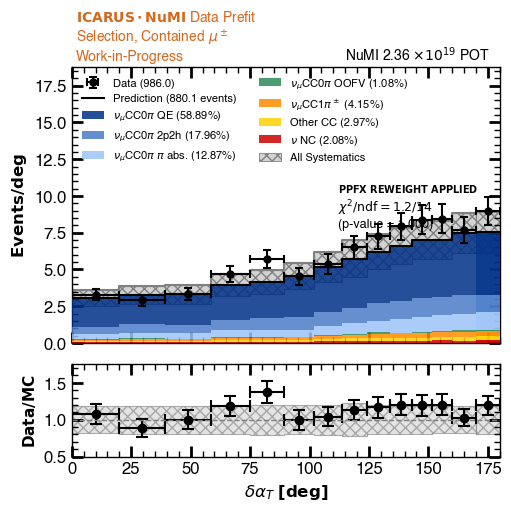

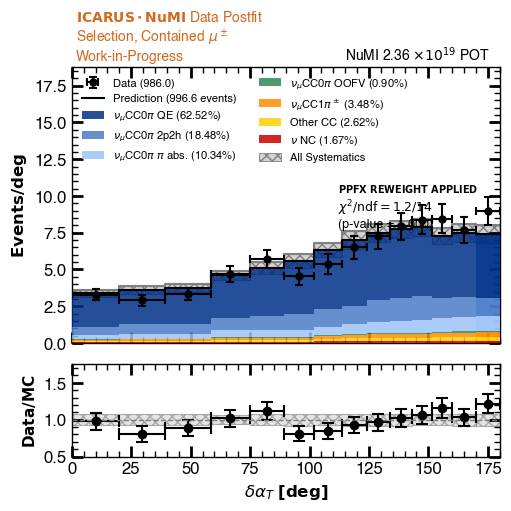

In [3]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/prefit_real_containment_dalphaT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    sample_name='selection_reco_dalphaT_contained',
    is_data=True,
    variable_name='reco_dalphaT_deg',
    cov_bin_range=(0, 14),  # selection contained: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/RealData_Containment/Prefits', save_name='prefit_dalphaT_selection_contained',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/postfit_real_containment_dalphaT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    sample_name='selection_reco_dalphaT_contained',
    is_data=True,
    variable_name='reco_dalphaT_deg',
    cov_bin_range=(0, 14),  # selection contained: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/dalphaT/RealData_Containment/Postfits', save_name='postfit_dalphaT_selection_contained'
)

## Selection - Exiting

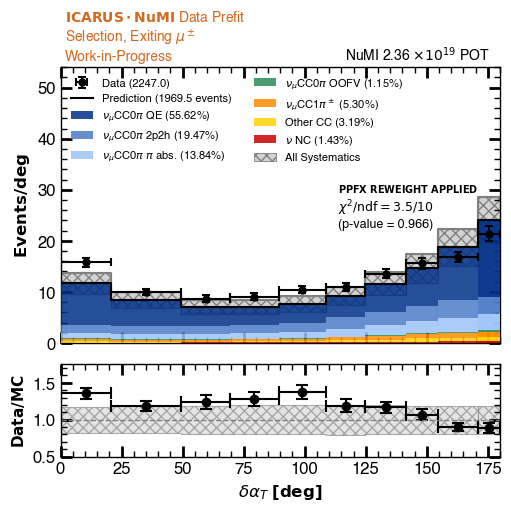

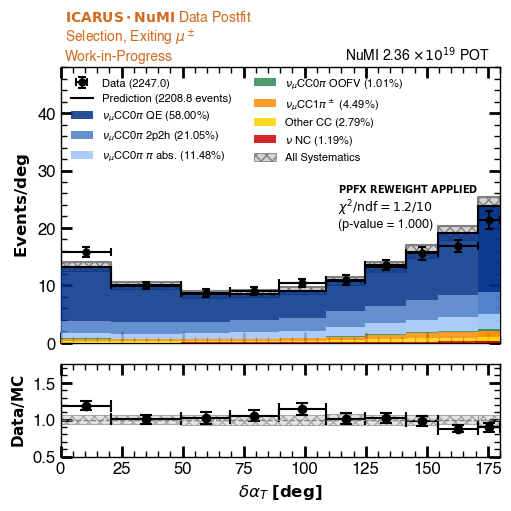

In [4]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/prefit_real_containment_dalphaT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    sample_name='selection_reco_dalphaT_exiting',
    is_data=True,
    variable_name='reco_dalphaT_deg',
    cov_bin_range=(14, 24),  # selection exiting: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/RealData_Containment/Prefits', save_name='prefit_dalphaT_selection_exiting',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/postfit_real_containment_dalphaT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    sample_name='selection_reco_dalphaT_exiting',
    is_data=True,
    variable_name='reco_dalphaT_deg',
    cov_bin_range=(14, 24),  # selection exiting: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/dalphaT/RealData_Containment/Postfits', save_name='postfit_dalphaT_selection_exiting'
)

## Sideband - Contained

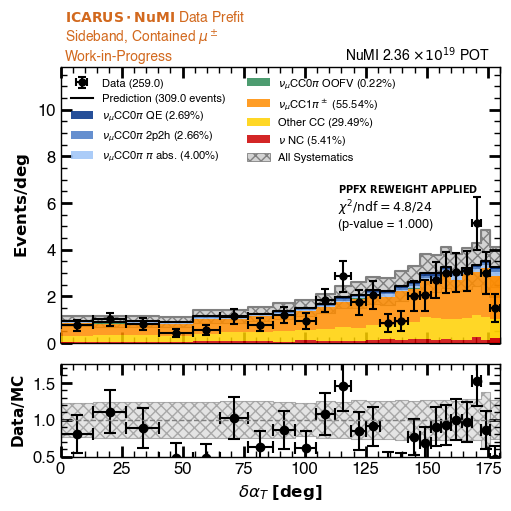

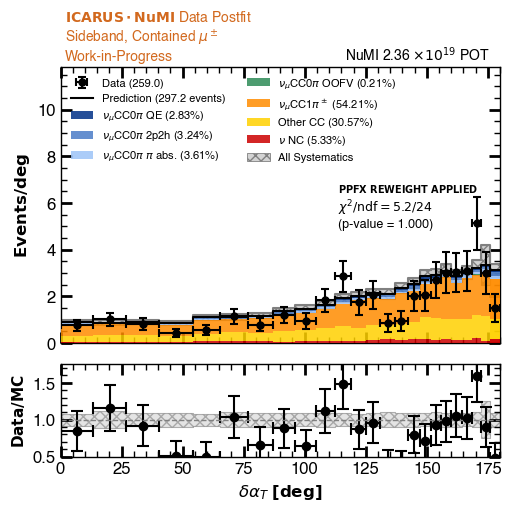

In [5]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/prefit_real_containment_dalphaT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    sample_name='sideband_reco_dalphaT_contained',
    is_data=True,
    variable_name='reco_dalphaT_deg',
    cov_bin_range=(24, 48),  # sideband contained: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/RealData_Containment/Prefits', save_name='prefit_dalphaT_sideband_contained',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/postfit_real_containment_dalphaT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    sample_name='sideband_reco_dalphaT_contained',
    is_data=True,
    variable_name='reco_dalphaT_deg',
    cov_bin_range=(24, 48),  # sideband contained: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/dalphaT/RealData_Containment/Postfits', save_name='postfit_dalphaT_sideband_contained'
)

## Sideband - Exiting

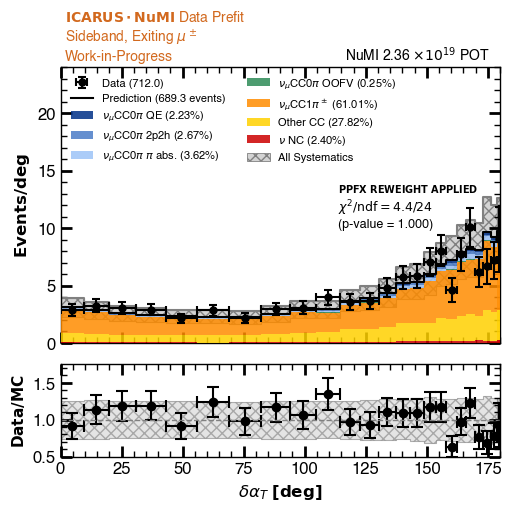

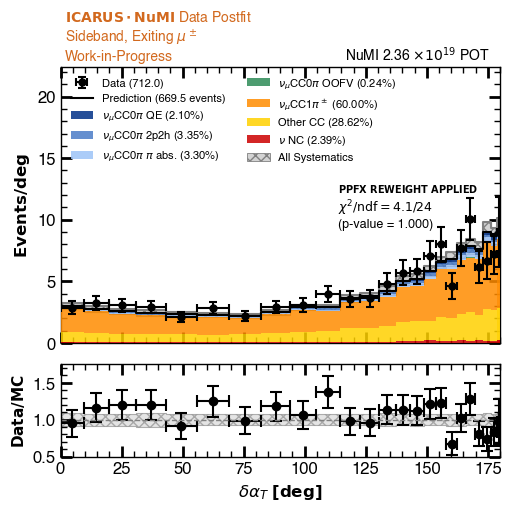

In [6]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/prefit_real_containment_dalphaT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    sample_name='sideband_reco_dalphaT_exiting',
    is_data=True,
    variable_name='reco_dalphaT_deg',
    cov_bin_range=(48, 72),  # sideband exiting: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/RealData_Containment/Prefits', save_name='prefit_dalphaT_sideband_exiting',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/postfit_real_containment_dalphaT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    sample_name='sideband_reco_dalphaT_exiting',
    is_data=True,
    variable_name='reco_dalphaT_deg',
    cov_bin_range=(48, 72),  # sideband exiting: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/dalphaT/RealData_Containment/Postfits', save_name='postfit_dalphaT_sideband_exiting'
)

## Cross-Section Extraction

Extracted from `real_containment_XSec_dalphaT.root`. It uses the true-level `True_dalphaT_XS` sample with 4 truth bins, which the reco-level containment split does not change. Units are cm$^2$/deg/Ar, scaled by $10^{40}$. Since $\delta\alpha_T$ is in degrees, no MeV to GeV conversion applies, and the truth binning has no overflow bin (`remove_last_bin=False`).


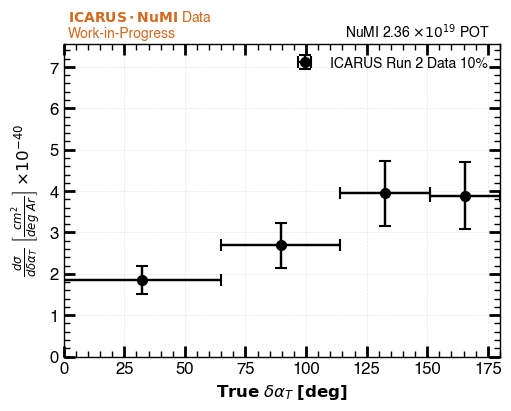

In [7]:
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/XSection/dalphaT/RealData_Containment/real_containment_XSec_dalphaT.root',
        is_cross_section = True,
        hist_path="calcXsec/histograms/True_dalphaT_XS_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta\alpha_T$ $\mathbf{[deg]}$',
        ylabel=r'$\frac{d\sigma}{d\delta\alpha_T}$ $\left[\frac{cm^2}{deg\ Ar}\right]$ $\times 10^{-40}$',
        bin_edges_labels=[0.0, 65.0, 114.0, 151.0, 180.0],
        remove_last_bin=False,
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        label="ICARUS Run 2 Data 10%",
        pot=r'NuMI 2.36 $\times 10^{19}$ POT',
        scaling_power_of_10=1e40
)
save_fig(fig_xs, r'../Plots/dalphaT/RealData_Containment/XSection', 'dalphaT_XS')


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.555173e+00
  65.0000 – 114.0000           2.155479e+00
  114.0000 – 151.0000           3.327037e+00
  151.0000 – 180.0000           3.964480e+00

χ² / Ndof = 2.4 / 4 = 0.602
p-value = 0.661


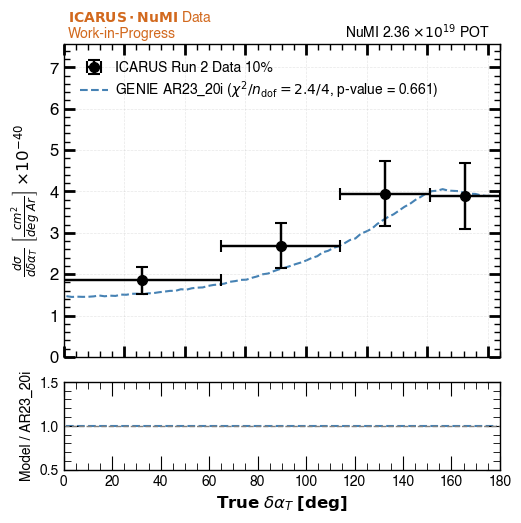

In [8]:
# Overlay GENIE with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
    bin_edges           = [0.0, 65.0, 114.0, 151.0, 180.0],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaalphaT',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dalphaT/RealData_Containment/XSection', 'dalphaT_XS_wGENIE')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.657399e+00
  65.0000 – 114.0000           2.392520e+00
  114.0000 – 151.0000           3.687243e+00
  151.0000 – 180.0000           4.089199e+00

χ² / Ndof = 0.8 / 4 = 0.203
p-value = 0.937


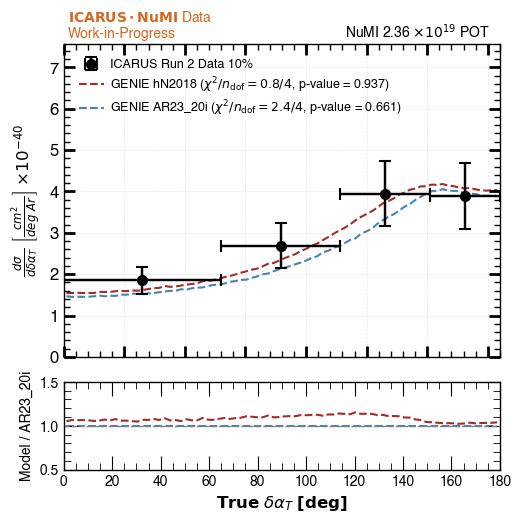

In [9]:
# Overlay GENIE hN2018 with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_hN2018/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_hN2018/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.0, 65.0, 114.0, 151.0, 180.0],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaalphaT',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE hN2018',
    color               = 'brown',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dalphaT/RealData_Containment/XSection', 'dalphaT_XS_wGENIE_hN2018')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.692559e+00
  65.0000 – 114.0000           2.341566e+00
  114.0000 – 151.0000           3.649691e+00
  151.0000 – 180.0000           4.421783e+00

χ² / Ndof = 1.2 / 4 = 0.306
p-value = 0.874


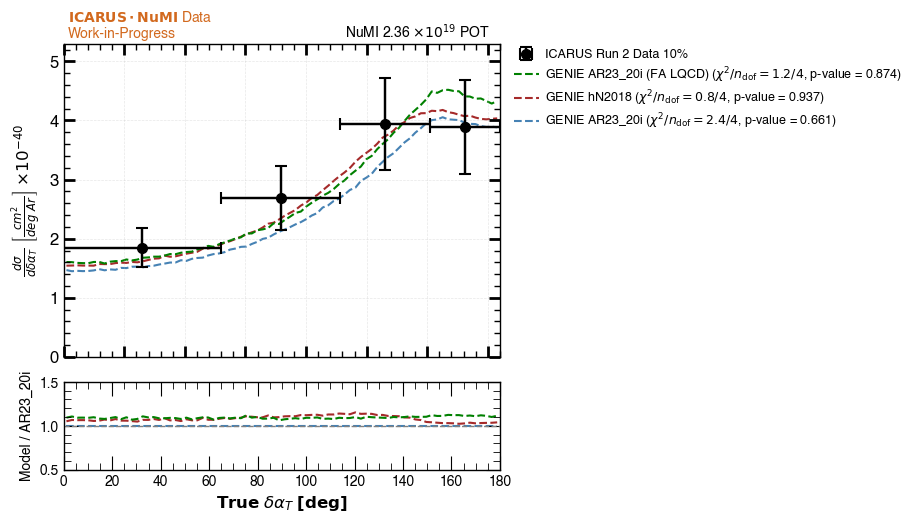

In [10]:
# Overlay GENIE LQCD with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_LQCD/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_LQCD/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.0, 65.0, 114.0, 151.0, 180.0],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaalphaT',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i (FA LQCD)',
    color               = 'green',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dalphaT/RealData_Containment/XSection', 'dalphaT_XS_wGENIE_LQCD')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.885810e+00
  65.0000 – 114.0000           2.593365e+00
  114.0000 – 151.0000           4.059685e+00
  151.0000 – 180.0000           4.951793e+00

χ² / Ndof = 1.8 / 4 = 0.455
p-value = 0.769


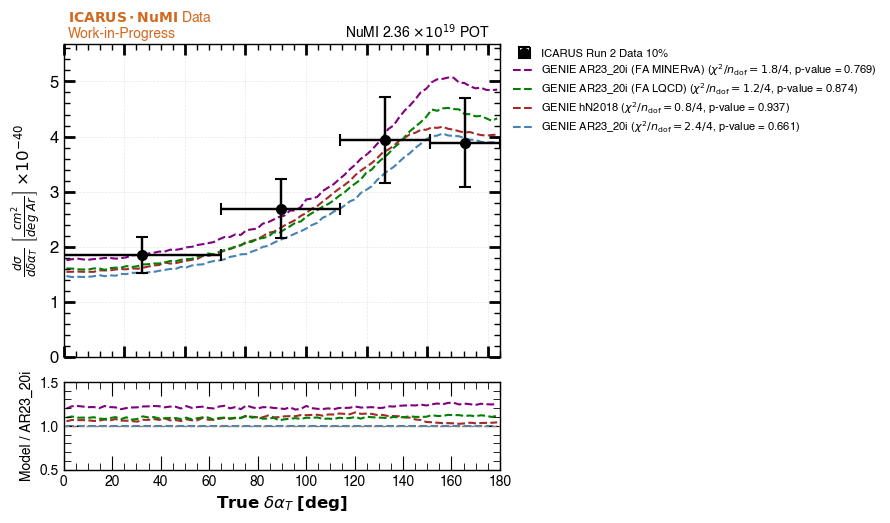

In [11]:
# Overlay GENIE MINERvA with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_MINERvA/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_MINERvA/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.0, 65.0, 114.0, 151.0, 180.0],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaalphaT',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i (FA MINERvA)',
    color               = 'purple',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dalphaT/RealData_Containment/XSection', 'dalphaT_XS_wGENIE_MINERvA')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.523753e+00
  65.0000 – 114.0000           2.238867e+00
  114.0000 – 151.0000           3.859011e+00
  151.0000 – 180.0000           4.535881e+00

χ² / Ndof = 2.3 / 4 = 0.582
p-value = 0.675


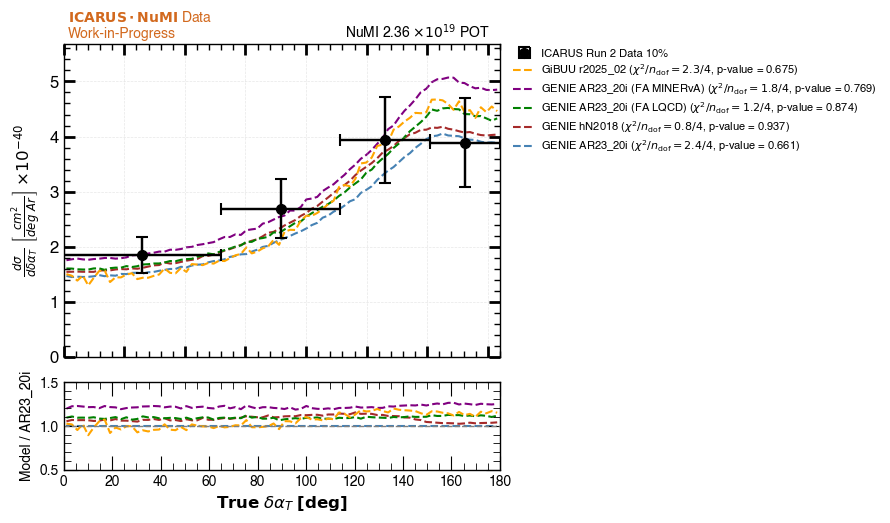

In [12]:
# Overlay GiBUU with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GiBUU/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GiBUU/fhc_Nu-14",
    generator_name      = 'GiBUU',
    bin_edges           = [0.0, 65.0, 114.0, 151.0, 180.0],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaalphaT',
    scaling_power_of_10 = 1e40,
    label               = 'GiBUU r2025_02',
    color               = 'orange',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dalphaT/RealData_Containment/XSection', 'dalphaT_XS_wGiBUU')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.885985e+00
  65.0000 – 114.0000           2.331962e+00
  114.0000 – 151.0000           3.046874e+00
  151.0000 – 180.0000           3.253177e+00

χ² / Ndof = 2.4 / 4 = 0.603
p-value = 0.661


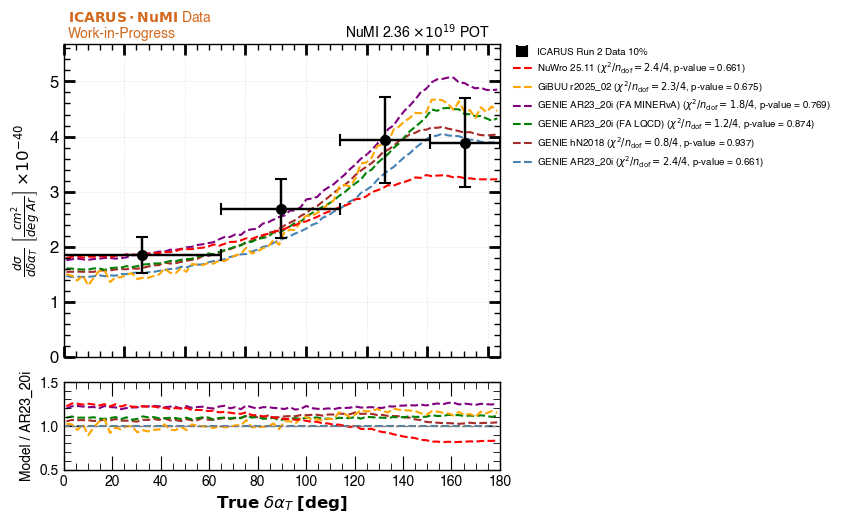

In [13]:
# Overlay NuWro with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NuWro/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NuWro/fhc_Nu-14",
    generator_name      = 'NuWro',
    bin_edges           = [0.0, 65.0, 114.0, 151.0, 180.0],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaalphaT',
    scaling_power_of_10 = 1e40,
    label               = 'NuWro 25.11',
    color               = 'red',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dalphaT/RealData_Containment/XSection', 'dalphaT_XS_wNuWro')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaalphaT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 65.0000           1.572598e+00
  65.0000 – 114.0000           2.163913e+00
  114.0000 – 151.0000           3.442814e+00
  151.0000 – 180.0000           4.123378e+00

χ² / Ndof = 2.1 / 4 = 0.537
p-value = 0.709


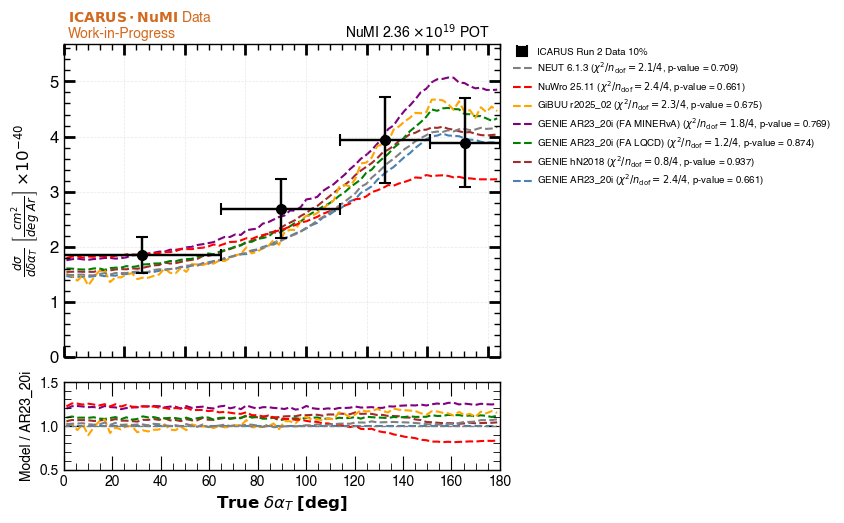

In [14]:
# Overlay NEUT with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NEUT/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NEUT/fhc_Nu-14",
    generator_name      = 'NEUT',
    bin_edges           = [0.0, 65.0, 114.0, 151.0, 180.0],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaalphaT',
    scaling_power_of_10 = 1e40,
    label               = 'NEUT 6.1.3',
    color               = 'gray',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dalphaT/RealData_Containment/XSection', 'dalphaT_XS_wNEUT')
display(fig_genie)

## Template Parameter Post-fit Values

One set of 4 template parameters, shared across all four samples -- not split by containment.

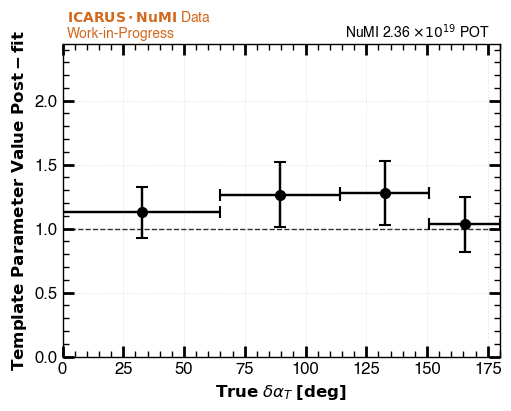

In [15]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_dalphaT_deg/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta\alpha_T$ $\mathbf{[deg]}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=[0.0, 65.0, 114.0, 151.0, 180.0],
        remove_last_bin=False,
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=r'NuMI 2.36 $\times 10^{19}$ POT'
)
save_fig(fig_template, r'../Plots/dalphaT/RealData_Containment/TemplateParameters', 'dalphaT')

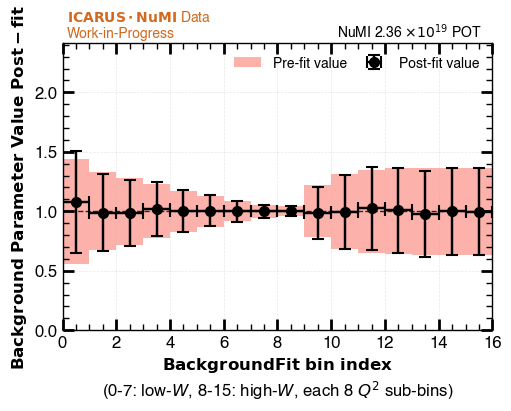

In [16]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=r'NuMI 2.36 $\times 10^{19}$ POT',
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/dalphaT/RealData_Containment/BackgroundFitParameters', 'dalphaT')

## Nuisance Parameter Constraints

Interaction-model, flux, and detector systematics -- one set of plots for the whole joint fit, unaffected by the reco-level split.

Number of parameters: 52


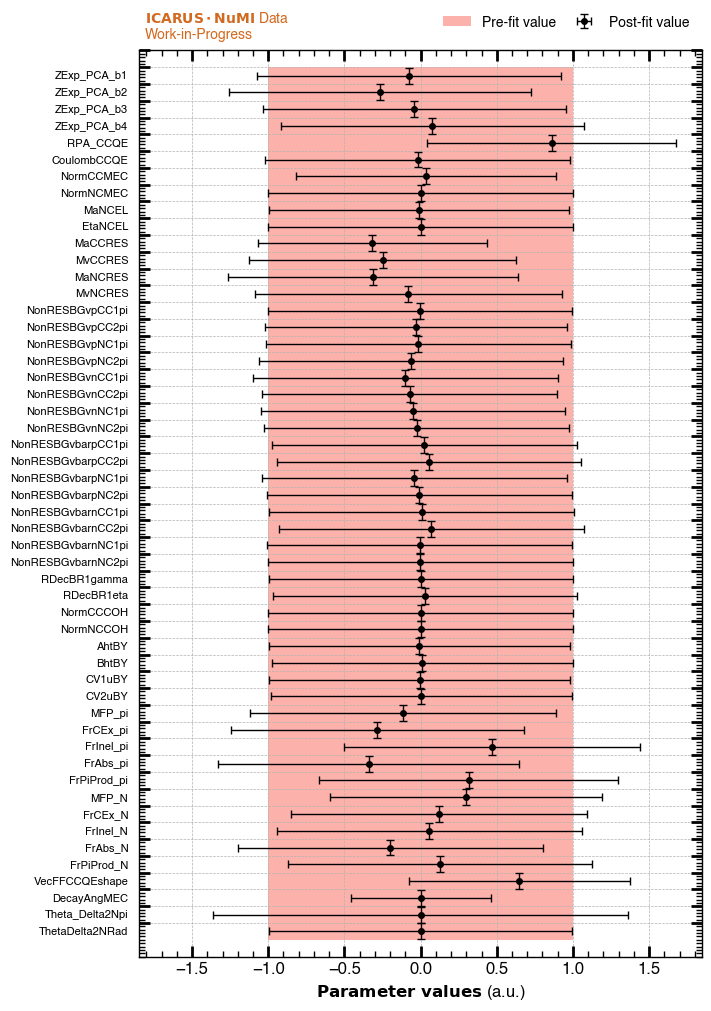

In [17]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 10),
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_InteractionModel')

Number of parameters: 27


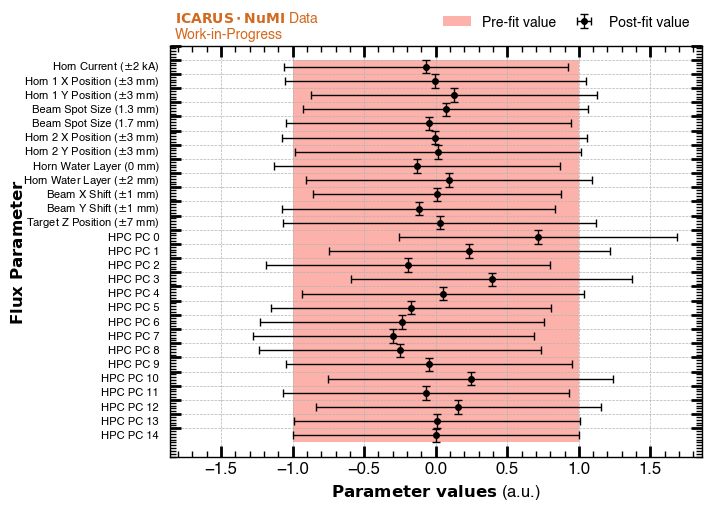

In [18]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 5),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_Flux')

Number of parameters: 9


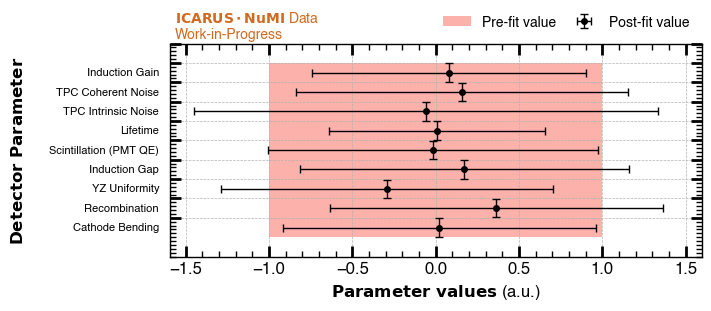

In [19]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_Detector')

Number of parameters: 14


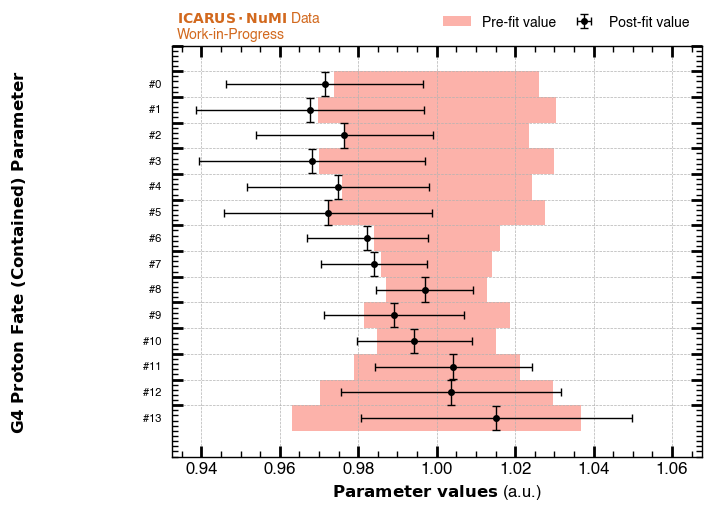

In [20]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (dalphaT, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_G4_Proton_Contained')

Number of parameters: 10


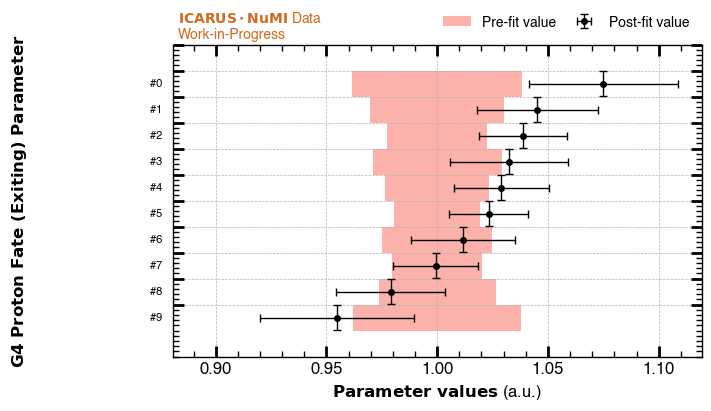

In [21]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (dalphaT, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_G4_Proton_Exiting')

Number of parameters: 14


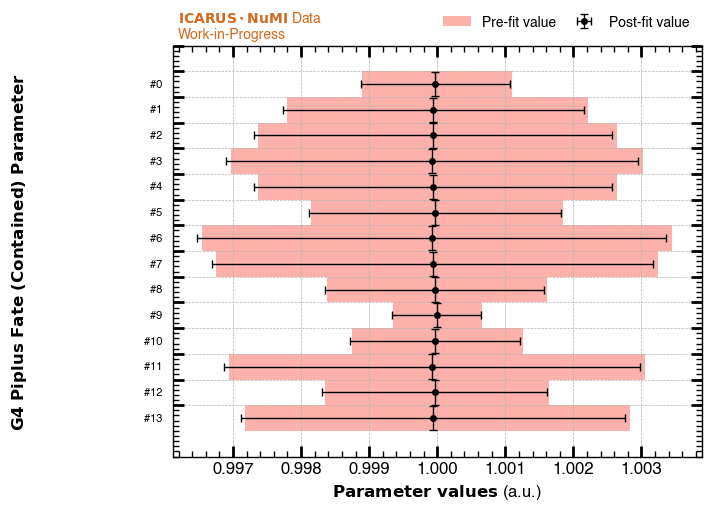

In [22]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (dalphaT, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_G4_Piplus_Contained')

Number of parameters: 10


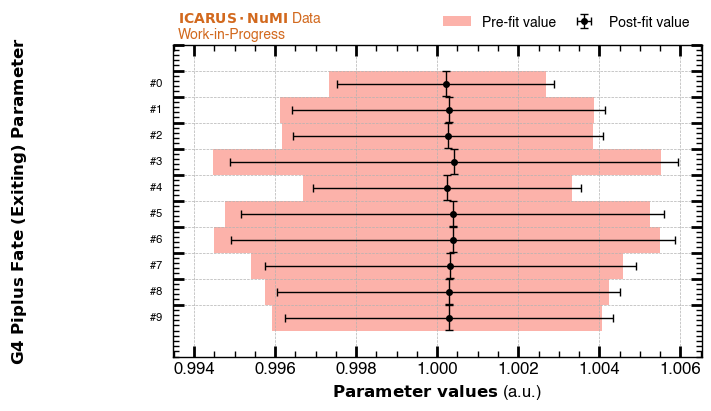

In [23]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (dalphaT, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_G4_Piplus_Exiting')

Number of parameters: 14


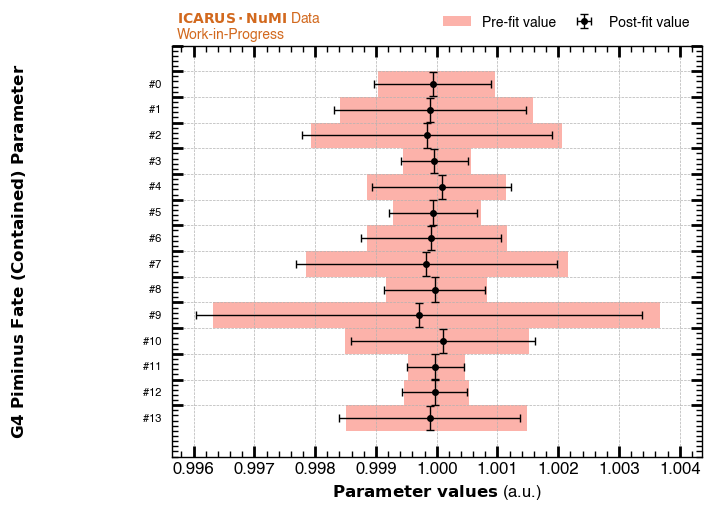

In [24]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (dalphaT, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_G4_Piminus_Contained')

Number of parameters: 10


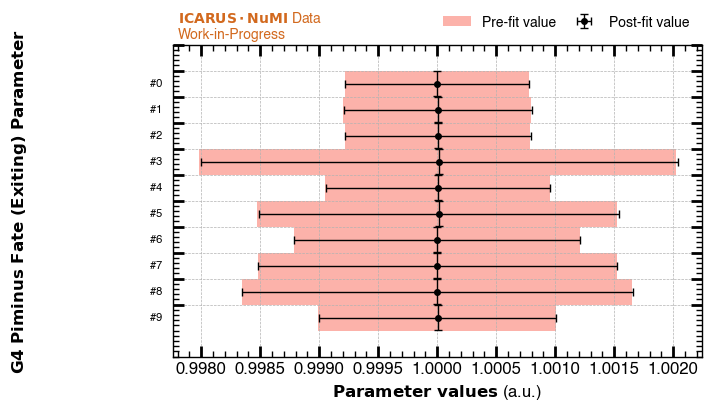

In [25]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (dalphaT, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/RealData_Containment/NuisanceParameters', 'dalphaT_G4_Piminus_Exiting')

## Covariance / Correlation Matrices

Per-systematic-block matrices -- among the nuisance parameters themselves, not among reco bins, so `bin_range` stays at its default (full block).

Full matrix size: 52×52


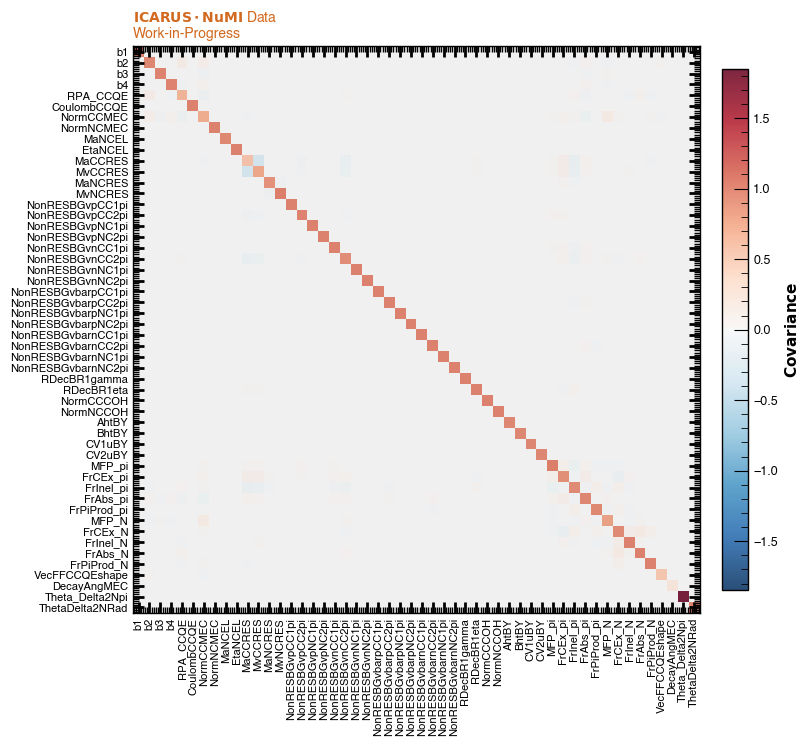

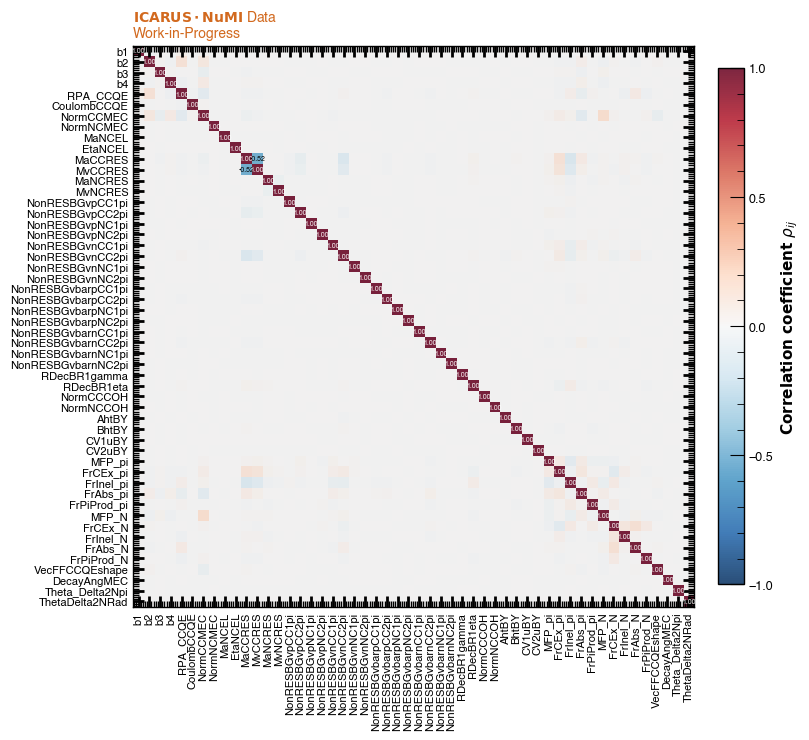

In [26]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(8, 20),
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


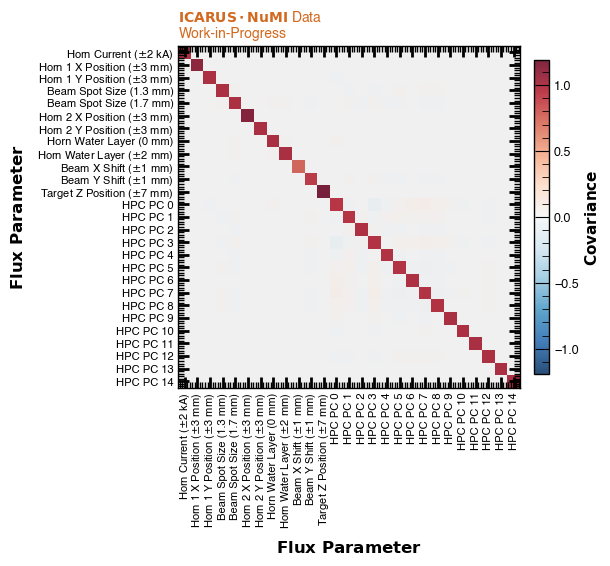

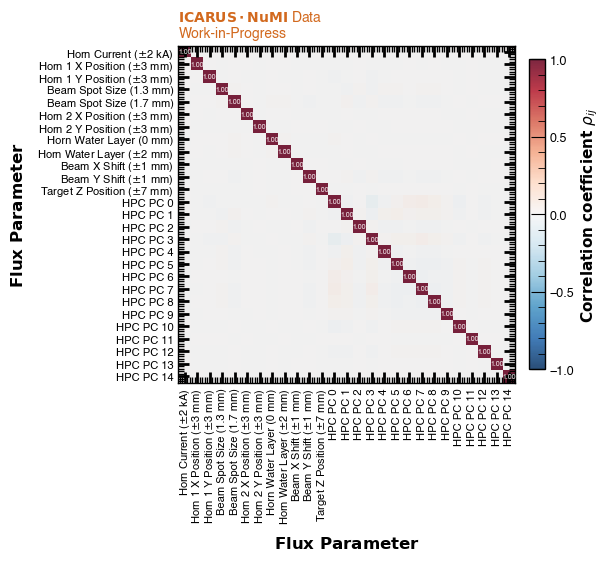

In [27]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


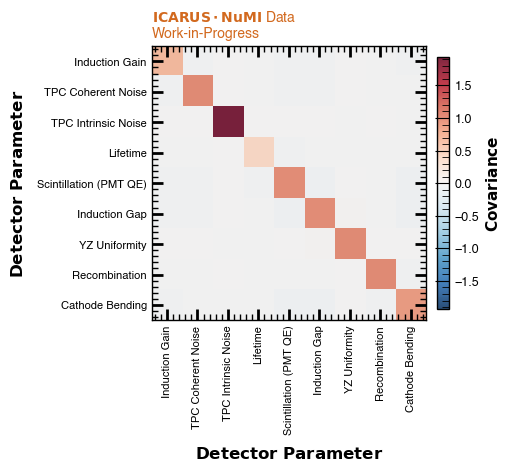

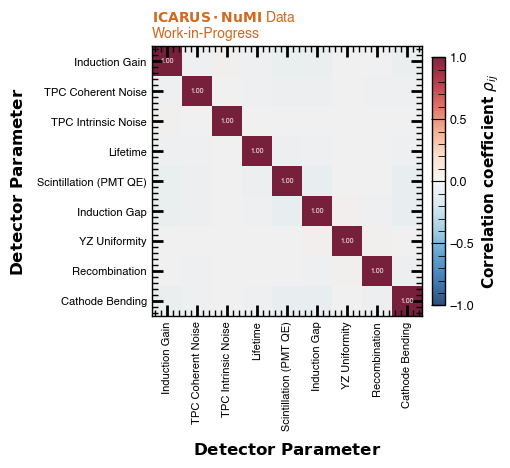

In [28]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'detector_param_correlation')

Full matrix size: 14×14


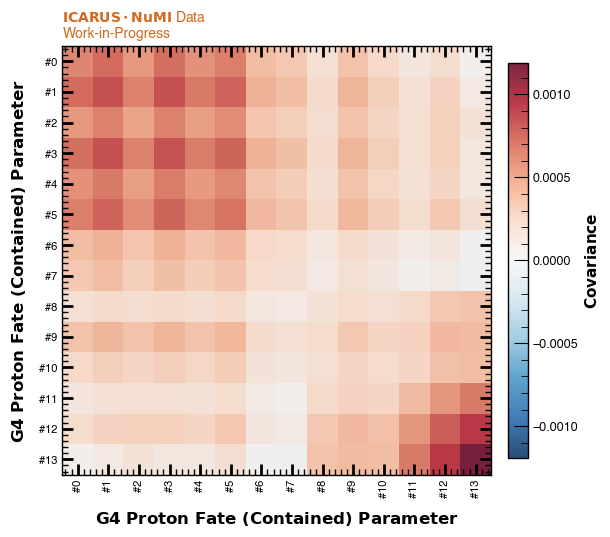

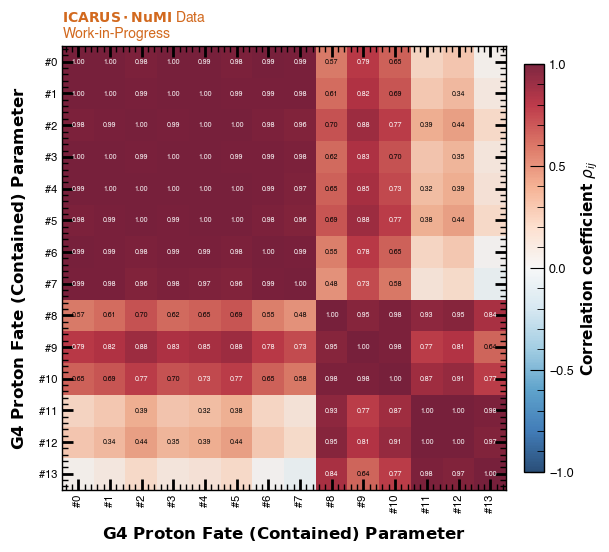

In [29]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (dalphaT, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (dalphaT, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_proton_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_proton_contained_param_correlation')

Full matrix size: 10×10


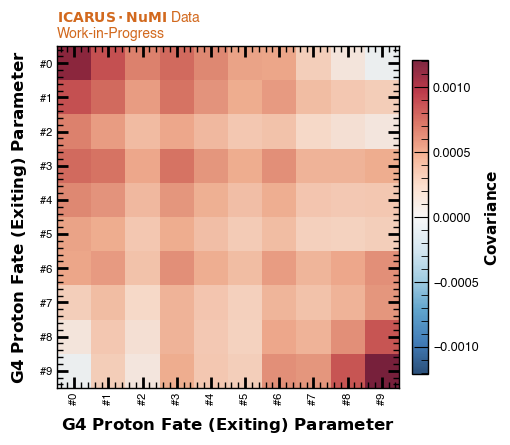

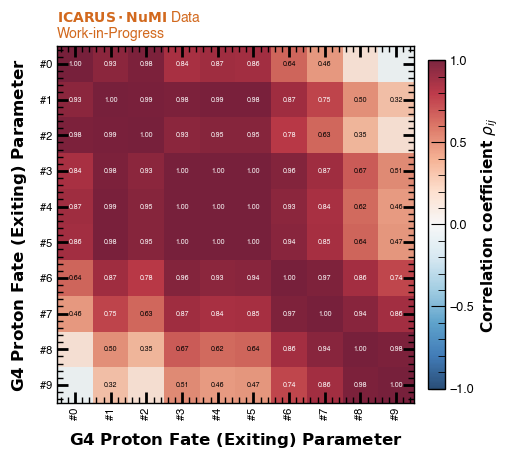

In [30]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(5, 9),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (dalphaT, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (dalphaT, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_proton_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_proton_exiting_param_correlation')

Full matrix size: 14×14


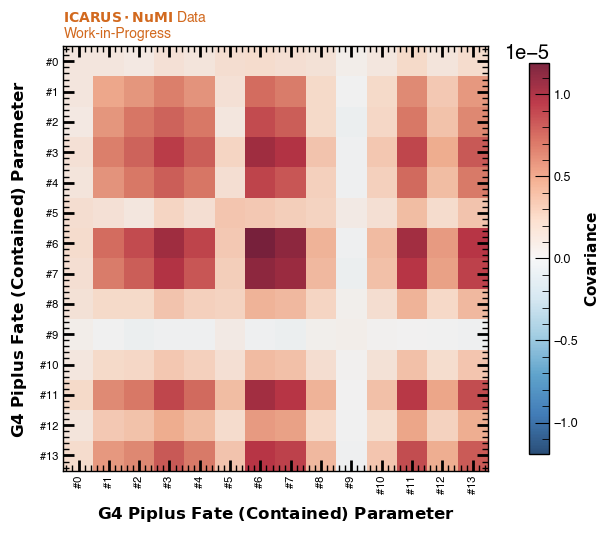

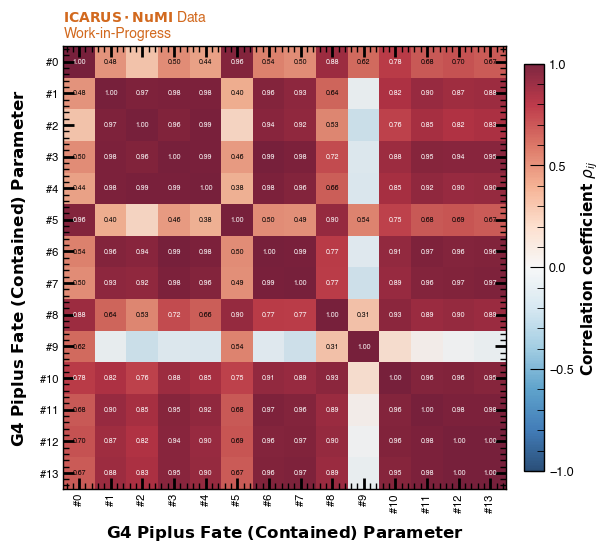

In [31]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (dalphaT, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (dalphaT, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_piplus_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_piplus_contained_param_correlation')

Full matrix size: 10×10


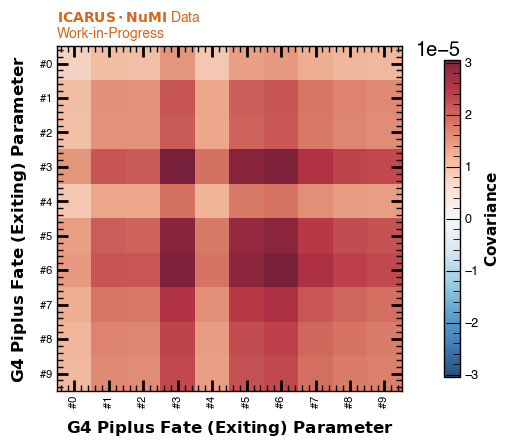

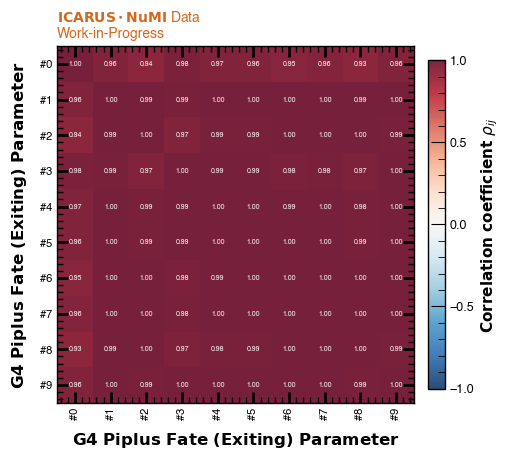

In [32]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(5, 9),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (dalphaT, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (dalphaT, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_piplus_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_piplus_exiting_param_correlation')

Full matrix size: 14×14


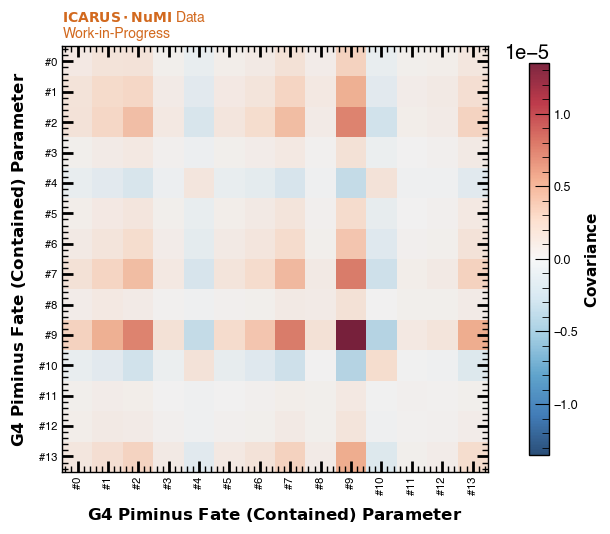

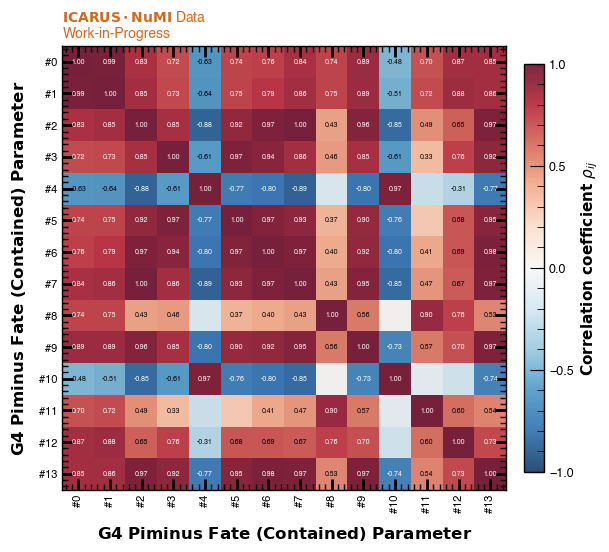

In [33]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (dalphaT, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (dalphaT, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_piminus_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_piminus_contained_param_correlation')

Full matrix size: 10×10


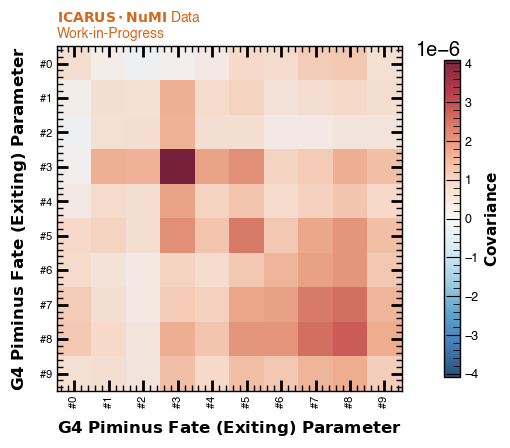

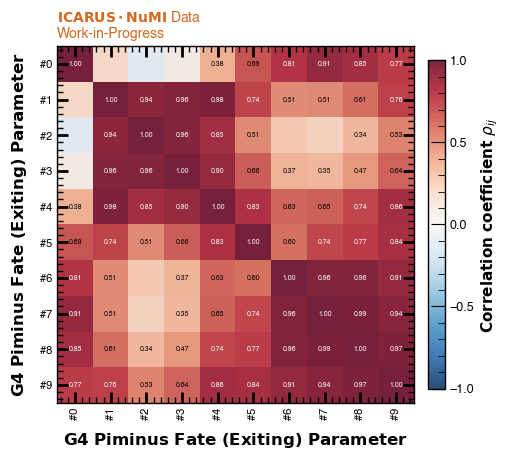

In [34]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(5, 9),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (dalphaT, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (dalphaT, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_piminus_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'g4_piminus_exiting_param_correlation')

## Full Covariance / Correlation Matrix (All Systematics + Template Parameters)

Single matrix over every free parameter in the fit -- template, background-fit, cross-section, flux, detector, and all six G4 groups -- read from the fitter's own postfit Hessian block (`FitterEngine/postFit/Hesse/hessian`), not the per-group `errors` blocks the cells above use. `annotate` is left off here since the matrix is too large for per-cell values to be legible.

In [35]:
BASE_ALL = "FitterEngine/postFit/Hesse/hessian"
GROUP_ORDER = [
    "Template Parameter true_dalphaT_deg",
    "Cross section Systematics",
    "Multisigma Flux Systematics",
    "Detector Systematics",
    "G4 Proton Fate (dalphaT, contained)",
    "G4 Proton Fate (dalphaT, exiting)",
    "G4 Piplus Fate (dalphaT, contained)",
    "G4 Piplus Fate (dalphaT, exiting)",
    "G4 Piminus Fate (dalphaT, contained)",
    "G4 Piminus Fate (dalphaT, exiting)",
    "BackgroundFit true_generator_w binbybin",
]
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dalphaT/RealData_Containment/real_containment_dalphaT.root',
    figsize=(30, 24),
    cov_path  = f"{BASE_ALL}/postfitCovariance_TH2D;1",
    corr_path = f"{BASE_ALL}/postfitCorrelation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=False,
    group_order=GROUP_ORDER,
    show_group_boundaries=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'all_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dalphaT/RealData_Containment/Postfits', 'all_param_correlation')

TypeError: plot_both_matrices() got an unexpected keyword argument 'show_group_boundaries'